# Nural-network from **Scratch**

### import library needed

In [26]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


### Network building 

- using **numpy** to initialize weights biases 

In [27]:
def init_weights(input_size,hidden_size,output_size):
    w1=np.random.randn(input_size,hidden_size)*0.01

    b1 = np.zeros((1, hidden_size))

    w2=np.random.randn(hidden_size,output_size)*0.01

    b2 = np.zeros((1, output_size))
    

    return w1,b1,w2,b2


- **Forward function will take the input and passed throught the network layer to compute the output**

In [28]:
def forward(X_train,w1,b1,w2,b2):
    """
    this function takes argument:
    x_train : input data
    w1 , b1 ,w2 ,b2 :network params
    return A1 ,Z1 ,A2 ,Z2
    """

       
    A1=np.dot(X_train,w1)+b1
    Z1=np.where(A1<=0,0,A1)
    A2=np.dot(Z1,w2)+b2
    Z2=np.exp(A2-np.max(A2,axis=1,keepdims=True))
    Z2/=np.sum(Z2,axis=1,keepdims=True)
    return A1 ,Z1 ,A2 ,Z2


- **backword function computing what each wieght need to decrease incase to decrease the loss using**
1- by passing the derivative Loss with respect to the  output  through all layer using chain rule enable it to compute
2- the derivative loss with respect to the weight which used to update the params

In [29]:
def backprop(X_train,Y_actul,A1,Z1,_,Z2,w2):
    """
    this function calculate the dervative of the weights and biases
    using them to update network params
    """
    n=X_train.shape[0]
    dz2=(Z2-Y_actul)
    dw2=(1/n)*Z1.T.dot(dz2)
    db2=(1/n)*np.sum(dz2,axis=0,keepdims=True)
    dz1 = dz2.dot(w2.T) * (A1 > 0)
    dw1=(1/n)*X_train.T.dot(dz1)
    db1=(1/n)*np.sum(dz1,axis=0,keepdims=True)
    
    return dw2,db2,dw1,db1

In [30]:
def nural_net(X_train,Y_train,hidden_size=100,lr=.1 ,iter=1000,l2_lambda=0.001,l1_lambda=0.001):
    from sklearn.preprocessing import OneHotEncoder
    n,input_size=X_train.shape
    oneHot=OneHotEncoder(sparse_output=False)
    Y_train = Y_train.reshape(-1, 1)
    y_oneHot=oneHot.fit_transform(Y_train)
    output_size=y_oneHot.shape[1]

    w1,b1,w2,b2=init_weights(input_size,hidden_size,output_size)

    for e in range(iter):

        A1 ,Z1,A2,Z2=forward(X_train,w1,b1,w2,b2)
        dw2,db2,dw1,db1=backprop(X_train,y_oneHot,A1,Z1,A2,Z2,w2)

        # applying penalty for large weights and useless features
        dw2 += l1_lambda * np.sign(w2) + l2_lambda * w2
        dw1 += l1_lambda * np.sign(w1) + l2_lambda * w1
        
        # update the network params
        w1-=lr*dw1
        b1-=lr*db1
        w2-=lr*dw2
        b2-=lr*db2

        # cliping wieghts for high stablity in training
        w1 = np.clip(w1, -1, 1)
        w2 = np.clip(w2, -1, 1)
        
        if e%100==0:
        #   decreasing learning rate by 1% each 100 epoch
          lr*=0.99
        #   decreasing regulization terms rate by 10% each 100 epoch gives the network freedom with time
          l2_lambda*=.9
          l1_lambda*=.9
        #   applying binary cross entroy to the outbut
          loss = -np.sum(y_oneHot * np.log(Z2 + 1e-9)) / n
          l2_loss = (l2_lambda / 2) * (np.sum(np.square(w1)) + np.sum(np.square(w2)))
          loss = loss + l2_loss
        #   print the loss with accuracy 
          predictions = np.argmax(Z2, axis=1)
          targets = np.argmax(y_oneHot, axis=1)
          accuracy = np.mean(predictions == targets)
          print(f'loss: {loss:.3f}, accuracy: {accuracy:.3f}')

    return w1,b1,w2,b2



    


In [31]:


x,y=load_digits(return_X_y=True)

# split the data into training and testing
X_train,X_test,Y_train,Y_test=train_test_split(x,y,test_size=.1,random_state=30)

w1,b1,w2,b2=nural_net(X_train,Y_train,lr=.01,iter=1000,hidden_size=412,l2_lambda=.000001,l1_lambda=.000001)





loss: 2.303, accuracy: 0.082
loss: 0.461, accuracy: 0.925
loss: 0.229, accuracy: 0.954
loss: 0.164, accuracy: 0.966
loss: 0.132, accuracy: 0.975
loss: 0.113, accuracy: 0.979
loss: 0.099, accuracy: 0.985
loss: 0.089, accuracy: 0.985
loss: 0.081, accuracy: 0.986
loss: 0.074, accuracy: 0.987


### testing the model

0.9722222222222222
Number of misclassified images: 5


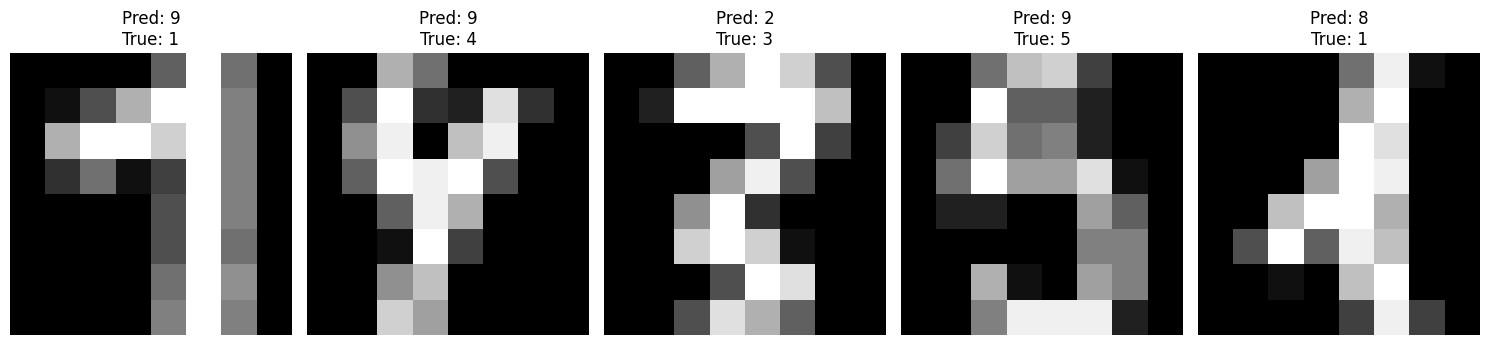

In [32]:
def get_pred(X_test):
    _,_,_,z2=forward(X_test,w1,b1,w2,b2)
    prediction=np.argmax(z2,axis=1)
    return prediction

predictions=get_pred(X_test)
accuracy = np.mean(predictions == Y_test)

print(accuracy)


misclassified_indices = np.where(predictions != Y_test)[0]
print(f"Number of misclassified images: {len(misclassified_indices)}")

plt.figure(figsize=(15, 5))
for i, idx in enumerate(misclassified_indices):
    plt.subplot(1, len(misclassified_indices), i + 1)
    plt.imshow(X_test[idx].reshape(8, 8), cmap='gray')
    plt.title(f'Pred: {predictions[idx]}\nTrue: {Y_test[idx]}')
    plt.axis('off')
plt.tight_layout()
plt.show()